# Session 1: The Uniform Distribution

*ECE 225A, Module 03 (Uniform and Exponential Distributions), deck 4.Uniform_distribution, slides 1-13*

Module 01 introduced continuous random variables in general. This module studies specific continuous families, starting with the simplest. A uniform variable has a constant density on an interval, so every probability is the area of a rectangle and every integral is easy. The family is still worth careful study. It shows how a density's constant is forced by normalization, how probabilities become ratios of lengths, and how shifting and scaling act on a density. It also demonstrates a strategy that returns with the normal distribution: analyze one standard member of the family, and transfer the results to the rest.

## Learning objectives

After this session you should be able to:

1. Define $U_{[a,b]}$, and derive the constant $1/(b - a)$ from normalization.
2. Write the piecewise CDF, and compute any interval probability as a ratio of lengths.
3. Show that uniformity is preserved by affine maps, and find the new interval and density, including for a negative slope.
4. Compute the mean and variance of $U_{[0,1]}$ by integration, and transfer them to $U_{[a,b]}$ with linearity and the variance rule.
5. Recognize situations that are well modeled as uniform, and spot those that only look uniform.

## Prerequisites

- PDF, CDF, and interval probabilities for continuous variables (Module 01, Session 5).
- LOTUS, linearity of expectation, and $V(X) = E[X^2] - (E[X])^2$ (Module 01, Sessions 3 and 4).
- The rule $V(aX + b) = a^2 V(X)$ (Module 01, Session 4).
- The change-of-variables formula $f_Y(y) = f_X(x)/\lvert g'(x) \rvert$ (Module 01, Session 5).

In [1]:
from fractions import Fraction
from math import sqrt

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad

rng = np.random.default_rng(225)

BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED, FAINT, GRID = "#0b0b0b", "#52514e", "#c3c2b7", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 1,
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
})


def show(label, v):
    # Print an exact value as a fraction and as a decimal.
    print(f"{label}: {v} = {float(v):.6f}")


def hist_vs_density(ax, sample, f, lo, hi, label, bins=50):
    # Compare a normalized histogram of a sample with a derived density.
    ax.hist(sample, bins=bins, range=(lo, hi), density=True, color=FAINT, label="simulated")
    grid = np.linspace(lo, hi, 400)
    ax.plot(grid, f(grid), color=BLUE, lw=2.5, label=label)

## 1. Definition (slides 1-2)

**Intuition.** Pick a point "at random" from an interval so that no part of the interval is favored. Equal lengths must get equal probability, which forces the density to be flat. Values outside the interval never occur, so the density there is 0.

**Formal definition.** For $a < b$, the **uniform distribution** $U_{[a,b]}$ has the density

$$f(x) = \begin{cases} c & x \in [a, b] \\ 0 & x \notin [a, b] \end{cases}$$

for some constant $c$. The first slide of the deck writes the top case as $[0, b]$, which is a typo for $[a, b]$.

The graph of $f$ is a rectangle, so every integral we need is just the area of a rectangle.

## 2. Finding $c$ (slide 3)

**Derivation.** A density must have total area 1:

$$1 = \int_{-\infty}^{\infty} f(x)\, dx = \int_a^b c \, dx = cx \Big|_a^b = c(b - a).$$

Therefore

$$c = \frac{1}{b - a}.$$

**Geometric view.** The rectangle has width $b - a$ and height $c$. Its area is $c(b - a)$, and setting that equal to 1 gives the same answer with no integral.

The longer the interval, the lower the density. A short interval makes it large: $U_{[0,\,1/4]}$ has density $4$, which is legal since a density is not a probability.

In [2]:
for a, b in [(0, 1), (2, 10), (0, 0.25), (-3, 3)]:
    c = 1 / (b - a)
    area, _ = quad(lambda x: c, a, b)
    print(f"U[{a}, {b}]: c = {c:.4f}, area = {area:.6f}")

U[0, 1]: c = 1.0000, area = 1.000000
U[2, 10]: c = 0.1250, area = 1.000000
U[0, 0.25]: c = 4.0000, area = 1.000000
U[-3, 3]: c = 0.1667, area = 1.000000


## 3. Who is uniform? (slide 4)

Uniform variables are the continuous versions of equally likely discrete outcomes. They arise when a value could equally well be anywhere in a bounded range:

- **Time.** You arrive at a stop without knowing the schedule of a bus or plane that departs at regular intervals. The wait is roughly uniform.
- **Location.** A defect on a chip is at a roughly uniform location in two dimensions, and a molecule in a container is at a roughly uniform location in three.
- **Small ranges.** Values confined to a small area, time, weight, or space can be approximately uniform, since a density that is smooth looks flat on a small scale.

Exact uniformity is less common than one might expect. Most naturally occurring quantities cluster around a typical value. Even the bus example fails if you know the schedule or if buses bunch up.

## 4. The CDF (slide 5)

**Derivation.** Integrate the density up to $x$, in three cases:

- For $x \le a$, no probability has accumulated: $F(x) = \int_{-\infty}^{x} 0\, du = 0$.
- For $a \le x \le b$, we add the rectangle of width $x - a$: $F(x) = F(a) + \int_a^x \frac{1}{b - a}\, du = \frac{x - a}{b - a}$.
- For $x \ge b$, all probability has accumulated: $F(x) = F(b) + \int_b^x 0\, du = 1$.

So

$$F(x) = \begin{cases} 0 & x < a \\ \dfrac{x - a}{b - a} & a \le x < b \\ 1 & x \ge b. \end{cases}$$

The CDF is a straight ramp from 0 at $a$ to 1 at $b$. Its slope is the height of the density, as $F' = f$ requires.

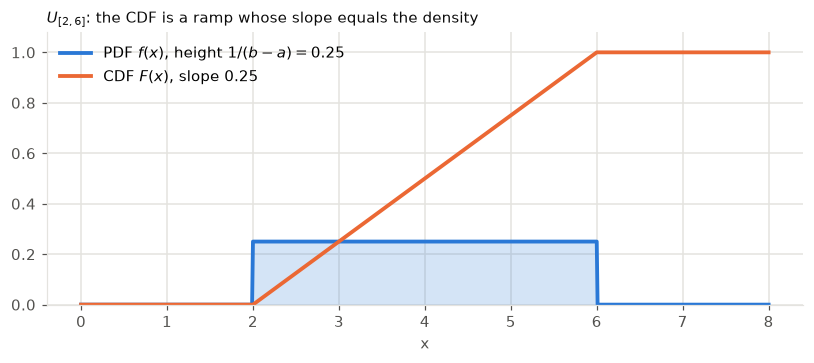

In [3]:
a, b = 2, 6
xs = np.linspace(0, 8, 801)
pdf = np.where((xs >= a) & (xs <= b), 1 / (b - a), 0)
cdf = np.clip((xs - a) / (b - a), 0, 1)

fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.fill_between(xs, pdf, color=BLUE, alpha=0.2, lw=0)
ax.plot(xs, pdf, color=BLUE, lw=2.5, label="PDF $f(x)$, height $1/(b - a) = 0.25$")
ax.plot(xs, cdf, color=ORANGE, lw=2.5, label="CDF $F(x)$, slope $0.25$")
ax.set(xlabel="x", ylim=(0, 1.08), xticks=range(9))
ax.legend(frameon=False, loc="upper left")
ax.set_title("$U_{[2,6]}$: the CDF is a ramp whose slope equals the density", color=INK, loc="left", fontsize=10)
plt.tight_layout()
plt.show()

## 5. Interval probabilities (slide 6)

Take $X \sim U_{[a,b]}$ with $a \le \alpha \le \beta \le b$. Interval probabilities can be computed from the CDF or read directly from the picture:

| Interval | As CDF difference | CDF values | Final |
|---|---|---|---|
| $(\alpha, \beta]$ | $F(\beta) - F(\alpha)$ | $\frac{\beta - a}{b - a} - \frac{\alpha - a}{b - a}$ | $\frac{\beta - \alpha}{b - a}$ |
| $(\beta, \infty)$ | $F(\infty) - F(\beta)$ | $1 - \frac{\beta - a}{b - a}$ | $\frac{b - \beta}{b - a}$ |
| $\lbrace \alpha \rbrace$ | $F(\alpha) - F(\alpha)$ | | $0$ |

All three cases say the same thing:

$$P(\text{interval}) = \frac{\text{length of the interval}}{\text{length of the domain}}.$$

This is the continuous analog of "favorable outcomes over total outcomes" from Module 01. Only the overlap with $[a, b]$ counts, so for an interval that sticks out of the domain, first cut it down to its part inside $[a, b]$.

In [4]:
a, b = 2, 6
alpha, beta = 3, 4.5
X = rng.uniform(a, b, size=1_000_000)

print(f"P({alpha} < X <= {beta}): exact {(beta - alpha) / (b - a):.4f}, simulated {np.mean((X > alpha) & (X <= beta)):.4f}")
print(f"P(X > {beta}):       exact {(b - beta) / (b - a):.4f}, simulated {np.mean(X > beta):.4f}")
print(f"P(X = {alpha}):         exact 0.0000, simulated {np.mean(X == alpha):.4f}")

P(3 < X <= 4.5): exact 0.3750, simulated 0.3746
P(X > 4.5):       exact 0.3750, simulated 0.3752
P(X = 3):         exact 0.0000, simulated 0.0000


## 6. Translation and scaling (slides 7 and 9)

**Claim.** If $X$ is uniform, then for all constants $a \ne 0$ and $b$, the variable $aX + b$ is also uniform. (In this section, $a$ and $b$ are the coefficients of the map, not the endpoints of an interval.)

**Setup.** Without loss of generality, take $X \sim U_{[0,1]}$ and $a > 0$, and show that $Y = aX + b \sim U_{[b,\,a + b]}$. The general case works in the same way.

**Range.** The map sends $0 \mapsto b$ and $1 \mapsto a + b$, so $Y \in [b, a + b]$.

**PDF.** Let $g(x) = ax + b$. The change-of-variables formula for an affine map gives

$$f_Y(y) = \frac{f_X(x)}{\lvert g'(x) \rvert} \Bigg|_{x = g^{-1}(y)} = \frac{1}{\lvert a \rvert} f_X\!\left(\frac{y - b}{a}\right) = \frac{1}{\lvert a \rvert}$$

on the range. This is constant, so $Y$ is uniform.

**Why it works.** The map stretches every interval by a factor of $\lvert a \rvert$, and the same probability now covers a length $\lvert a \rvert$ times larger. So the density falls by a factor of $\lvert a \rvert$ everywhere, and a flat density stays flat.

A negative $a$ also reverses the interval. For example, $-X \sim U_{[-1,\,0]}$, and more generally, $a < 0$ gives $Y \sim U_{[a + b,\,b]}$.

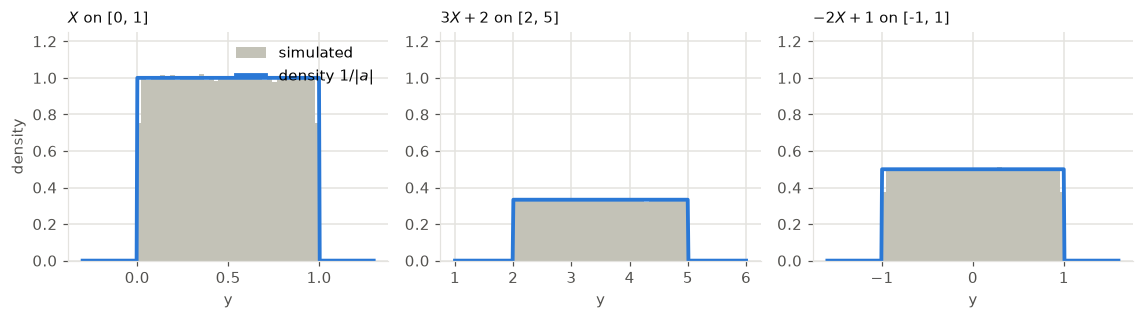

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(10.5, 3))
X01 = rng.uniform(0, 1, size=500_000)

maps = [("$X$", 1, 0, (-0.3, 1.3)), ("$3X + 2$", 3, 2, (1, 6)), ("$-2X + 1$", -2, 1, (-1.6, 1.6))]
for ax, (name, a, b, (lo, hi)) in zip(axes, maps):
    left, right = sorted([b, a + b])
    f = lambda y, l=left, r=right: np.where((y >= l) & (y <= r), 1 / (r - l), 0.0)
    hist_vs_density(ax, a * X01 + b, f, lo, hi, f"density $1/|a|$", bins=60)
    ax.set_title(f"{name} on [{left}, {right}]", color=INK, loc="left", fontsize=10)
    ax.set(xlabel="y", ylim=(0, 1.25))
axes[0].legend(frameon=False, loc="upper right")
axes[0].set_ylabel("density")
plt.tight_layout()
plt.show()

## 7. The plan for $\mu$ and $\sigma$ (slide 8)

We want the mean and standard deviation of every $U_{[a,b]}$. Integrating for general $a, b$ is possible but messy, so use the closure property from Section 6:

1. Relate $U_{[a,b]}$ to the single standard case $U_{[0,1]}$.
2. Find $\mu$ and $\sigma$ of $U_{[0,1]}$, where the integrals are trivial.
3. Infer the general result from linearity of expectation and the variance rule.

This pattern, solving one standard case and transferring the result, is the main strategy for the normal distribution in Module 04.

## 8. $\mu$ and $\sigma$ of $U_{[0,1]}$ (slide 10)

Let $X \sim U_{[0,1]}$, so $f(x) = 1$ for $0 \le x \le 1$. By direct integration:

$$E[X] = \int_0^1 x \, dx = \frac{x^2}{2} \Big|_0^1 = \frac{1}{2},$$

which also follows from symmetry around $1/2$.

$$E[X^2] = \int_0^1 x^2 \, dx = \frac{x^3}{3} \Big|_0^1 = \frac{1}{3},$$

$$V(X) = E[X^2] - (E[X])^2 = \frac{1}{3} - \frac{1}{4} = \frac{1}{12},$$

$$\sigma = \sqrt{\frac{1}{12}} = \frac{1}{2\sqrt{3}} \approx 0.29.$$

In [6]:
mean, _ = quad(lambda x: x, 0, 1)
second, _ = quad(lambda x: x ** 2, 0, 1)
print(f"numerical: E[X] = {mean:.6f}, E[X^2] = {second:.6f}, V(X) = {second - mean ** 2:.6f}")
show("exact V(X)", Fraction(1, 3) - Fraction(1, 4))
print(f"std: {1 / (2 * sqrt(3)):.6f}")
print(f"simulated: mean {X01.mean():.4f}, variance {X01.var():.4f}, std {X01.std():.4f}")

numerical: E[X] = 0.500000, E[X^2] = 0.333333, V(X) = 0.083333
exact V(X): 1/12 = 0.083333
std: 0.288675
simulated: mean 0.4993, variance 0.0834, std 0.2888


## 9. General $\mu$ and $\sigma$ (slide 11)

If $X \sim U_{[0,1]}$, then $Y = (b - a)X + a \sim U_{[a,b]}$ by Section 6, with the map's slope $b - a$ and intercept $a$. Now transfer the results.

**Mean, by linearity.**

$$E[Y] = (b - a)E[X] + a = \frac{b - a}{2} + a = \frac{a + b}{2},$$

which is the average of the endpoints, or the center of the rectangle.

**Variance, by the variance rule.**

$$V(Y) = V\big[(b - a)X + a\big] = (b - a)^2 V(X) = \frac{(b - a)^2}{12}.$$

**Standard deviation.**

$$\sigma = \frac{b - a}{2\sqrt{3}} \approx 0.29\,(b - a).$$

So the standard deviation of any uniform is about 29% of the length of its interval, wherever it sits. The translation $a$ affects the mean but not the spread.

In [7]:
print("interval      mean: exact, simulated       std: exact, simulated")
for a, b in [(0, 1), (2, 6), (-3, 3), (10, 110)]:
    Y = (b - a) * X01 + a
    print(f"[{a:3d},{b:4d}]    {(a + b) / 2:8.3f}  {Y.mean():8.3f}          {(b - a) / (2 * sqrt(3)):8.3f}  {Y.std():8.3f}")

interval      mean: exact, simulated       std: exact, simulated
[  0,   1]       0.500     0.499             0.289     0.289
[  2,   6]       4.000     3.997             1.155     1.155
[ -3,   3]       0.000    -0.004             1.732     1.733
[ 10, 110]      60.000    59.928            28.868    28.878


## 10. Celsius to Fahrenheit (slide 12)

**Problem.** A temperature in Celsius is $X \sim U_{[0,1]}$. What is its distribution in Fahrenheit?

**Solution.** The conversion is affine, $Y = \frac{9}{5}X + 32$, which is pinned down by $0 \mapsto 32$ and $100 \mapsto 212$. So:

- **Family:** by Section 6, $Y$ is uniform.
- **Range:** $0 \mapsto 32$ and $1 \mapsto 33.8$, so $Y \in [32, 33.8]$.
- **Density:** $f_Y(y) = \frac{1}{\lvert 9/5 \rvert} f_X\!\left(\frac{y - 32}{9/5}\right) = \frac{5}{9}$ on the range, which matches $\frac{1}{33.8 - 32} = \frac{5}{9}$.

So $Y \sim U_{[32,\,33.8]}$. A degree Fahrenheit is smaller than a degree Celsius, so the same range covers more degrees and the density falls.

In [8]:
C = rng.uniform(0, 1, size=1_000_000)
F = 9 / 5 * C + 32
print(f"range: [{F.min():.4f}, {F.max():.4f}]  (exact [32, 33.8])")
print(f"mean: {F.mean():.4f} (exact {(32 + 33.8) / 2}), std: {F.std():.4f} (exact {1.8 / (2 * sqrt(3)):.4f})")
print(f"density in the middle of the range: {np.mean((F > 32.8) & (F < 33)) / 0.2:.4f} (exact {5 / 9:.4f})")

range: [32.0000, 33.8000]  (exact [32, 33.8])
mean: 32.8993 (exact 32.9), std: 0.5197 (exact 0.5196)
density in the middle of the range: 0.5508 (exact 0.5556)


## Common pitfalls

1. **Treating the density as a probability.** $U_{[0,\,1/4]}$ has density 4, and that is fine. Probabilities are lengths times the density, and $P(X = x) = 0$.
2. **Forgetting to clip an interval to the domain.** For $X \sim U_{[0,1]}$, $P(X \le 3) = 1$ and not $3$. Use only the overlap with $[a, b]$.
3. **Dropping $1/\lvert a \rvert$ in the density of $aX + b$.** A stretched variable has a smaller density. Check that the new rectangle still has area 1.
4. **Forgetting the interval flips for $a < 0$.** $-2X + 1$ with $X \sim U_{[0,1]}$ is uniform on $[-1, 1]$, not on $[1, -1]$.
5. **Assuming any function of a uniform is uniform.** Only special maps preserve uniformity. $X^2$ has density $1/(2\sqrt{y})$ on $(0, 1]$.
6. **Mixing up $\sigma$ and the range.** $V = (b - a)^2/12$, so $\sigma \approx 0.29(b - a)$. A common slip is $V = (b - a)/12$.
7. **Assuming the model holds just because a value is unknown.** Not knowing a value does not make it uniform. Being unsure of tomorrow's high temperature does not make all temperatures equally likely.

## Key takeaways

- **Definition:** $U_{[a,b]}$ has density $\frac{1}{b - a}$ on $[a, b]$ and 0 elsewhere. All integrals are areas of rectangles.
- **CDF:** a ramp, $F(x) = \frac{x - a}{b - a}$ on $[a, b]$, and 0 before, 1 after.
- **Probabilities:** interval length over domain length, and $P(X = x) = 0$.
- **Closure:** $aX + b$ is uniform, with density reduced by $\lvert a \rvert$. Every uniform is an affine image of $U_{[0,1]}$.
- **Moments:** $\mu = \frac{a + b}{2}$, $V = \frac{(b - a)^2}{12}$, and $\sigma = \frac{b - a}{2\sqrt{3}} \approx 0.29(b - a)$, found from $U_{[0,1]}$ by linearity and the variance rule.
- **Example:** $X \sim U_{[0,1]}$ degrees Celsius is $U_{[32,\,33.8]}$ degrees Fahrenheit, with density $5/9$.
- Next: Session 2 studies the exponential distribution, the continuous limit of the geometric, where unlike here the remaining wait does not depend on the wait so far.